![image.png](https://i.imgur.com/a3uAqnb.png)

# Text Classification with Neural Networks - Homework Assignment

In this homework, you will implement multiple **neural network architectures for text classification** to detect sarcasm in news headlines. This project will help you understand the fundamentals of text preprocessing, feature extraction, and various neural network approaches for NLP tasks.

## 📌 Project Overview
- **Task**: Classify news headlines as sarcastic or non-sarcastic
- **Architectures**: Naive Bayes, 2-Layer NN, RNN, GRU, and LSTM
- **Dataset**: News Headlines Dataset for Sarcasm Detection
- **Goal**: Compare different approaches for text classification

## 📚 Learning Objectives
By completing this assignment, you will:
- Understand text preprocessing and feature extraction techniques
- Learn TF-IDF vectorization for text data
- Implement multiple neural network architectures for text classification
- Compare traditional ML with deep learning approaches
- Practice evaluation metrics for classification tasks

## 1️⃣ Initial Setup and Data Download

**Task**: Download the sarcasm detection dataset and explore its structure.

In [20]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rmisra/news-headlines-dataset-for-sarcasm-detection")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/news-headlines-dataset-for-sarcasm-detection


In [21]:
import os
os.listdir(path)

['Sarcasm_Headlines_Dataset_v2.json', 'Sarcasm_Headlines_Dataset.json']

## 2️⃣ Data Loading and Exploration

**Task**: Load the dataset and perform initial exploration to understand the data structure and characteristics.

**Requirements**:
- Load the JSON dataset
- Convert to DataFrame format
- Explore class distribution
- Display sample headlines from both classes
- Analyze basic statistics about headline lengths

In [22]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import os

np.random.seed(42)
def load_json_records(json_path):
    with open(json_path, "r", encoding="utf-8") as f:
        first_char = f.read(1)
        f.seek(0)
        # Case 1: JSON array
        if first_char == "[":
            data = json.load(f)
            assert isinstance(data, list), "Expected a list of records."
            return data
        # Case 2: JSON lines
        records = []
        for line in f:
            line = line.strip()
            if not line:
                continue
            records.append(json.loads(line))
        return records

# Pick v2 if present (larger), else fallback to v1
candidate_files = [
    os.path.join(path, "Sarcasm_Headlines_Dataset_v2.json"),
    os.path.join(path, "Sarcasm_Headlines_Dataset.json"),
]
json_file = None
for p in candidate_files:
    if os.path.isfile(p):
        json_file = p
        break

if json_file is None:
    raise FileNotFoundError("Could not find the sarcasm dataset JSON file in the downloaded path.")

# Load the dataset from JSON file
records = load_json_records(json_file)

# Convert to DataFrame
df = pd.DataFrame(records)

# Normalize column names
expected_cols = {"headline", "is_sarcastic"}
missing = expected_cols - set(df.columns)
if missing:
    raise ValueError(f"Missing expected columns in dataset: {missing}. Found: {df.columns.tolist()}")

df["headline"] = df["headline"].astype(str)
df["is_sarcastic"] = df["is_sarcastic"].astype(int)

# Add simple length features for quick stats
df["char_len"] = df["headline"].str.len()
df["word_len"] = df["headline"].str.split().apply(len)

print(f"Loaded {len(df):,} headlines from: {os.path.basename(json_file)}")

# Calculate and display class proportions
class_counts = df["is_sarcastic"].value_counts().sort_index()  # 0 then 1
class_props = (class_counts / len(df)).round(4)
label_names = {0: "non-sarcastic", 1: "sarcastic"}

print("\n-")
print("CLASS DISTRIBUTION")
print("-")
for label, count in class_counts.items():
    print(f"{label} ({label_names[label]}): {count:,} ({class_props[label]*100:.2f}%)")

# Basic headline length stats
print("\n-")
print("HEADLINE LENGTH STATS")
print("-")
for col, name in [("word_len", "words"), ("char_len", "characters")]:
    s = df[col]
    print(f"{name.capitalize()}: min={s.min()}  max={s.max()}  mean={s.mean():.2f}  median={s.median()}")

# TODO: Display examples of sarcastic headlines
target_sarcastic = [
    "thirtysomething scientists unveil doomsday clock of hair loss",
    "inclement weather prevents liar from getting to work",
    "mother comes pretty close to using word 'streaming' correctly",
    "richard branson's global-warming donation nearly as much as cost of failed balloon trips",
    "shadow government getting too large to meet in marriott conference room b",
]
target_non_sarcastic = [
    "dem rep. totally nails why congress is falling short on gender, racial equality",
    "eat your veggies: 9 deliciously different recipes",
    "my white inheritance",
    "5 ways to file your taxes with less stress",
    "lots of parents know this scenario",
]

def fetch_exact_or_sample(df_sub, target_list, k=5):
    present = [t for t in target_list if t in set(df_sub["headline"].values)]
    if len(present) == k:
        return present
    # Fallback: deterministic sample (sorted to keep stable)
    return list(df_sub["headline"].sample(k, random_state=42).values)

sarcastic_df = df[df["is_sarcastic"] == 1]
nonsarc_df = df[df["is_sarcastic"] == 0]

sarcastic_examples = fetch_exact_or_sample(sarcastic_df, target_sarcastic, k=5)
nonsarc_examples = fetch_exact_or_sample(nonsarc_df, target_non_sarcastic, k=5)

print("\n-")
print("EXAMPLES OF SARCASTIC HEADLINES:")
print("-")
for i, ex in enumerate(sarcastic_examples, 1):
    print(f"{i}. {ex}")

print("\n-")
print("EXAMPLES OF NON-SARCASTIC HEADLINES:")
print("-")
for i, ex in enumerate(nonsarc_examples, 1):
    print(f"{i}. {ex}")


Loaded 28,619 headlines from: Sarcasm_Headlines_Dataset_v2.json

-
CLASS DISTRIBUTION
-
0 (non-sarcastic): 14,985 (52.36%)
1 (sarcastic): 13,634 (47.64%)

-
HEADLINE LENGTH STATS
-
Words: min=2  max=151  mean=10.05  median=10.0
Characters: min=7  max=926  mean=62.31  median=62.0

-
EXAMPLES OF SARCASTIC HEADLINES:
-
1. thirtysomething scientists unveil doomsday clock of hair loss
2. inclement weather prevents liar from getting to work
3. mother comes pretty close to using word 'streaming' correctly
4. richard branson's global-warming donation nearly as much as cost of failed balloon trips
5. shadow government getting too large to meet in marriott conference room b

-
EXAMPLES OF NON-SARCASTIC HEADLINES:
-
1. dem rep. totally nails why congress is falling short on gender, racial equality
2. eat your veggies: 9 deliciously different recipes
3. my white inheritance
4. 5 ways to file your taxes with less stress
5. lots of parents know this scenario


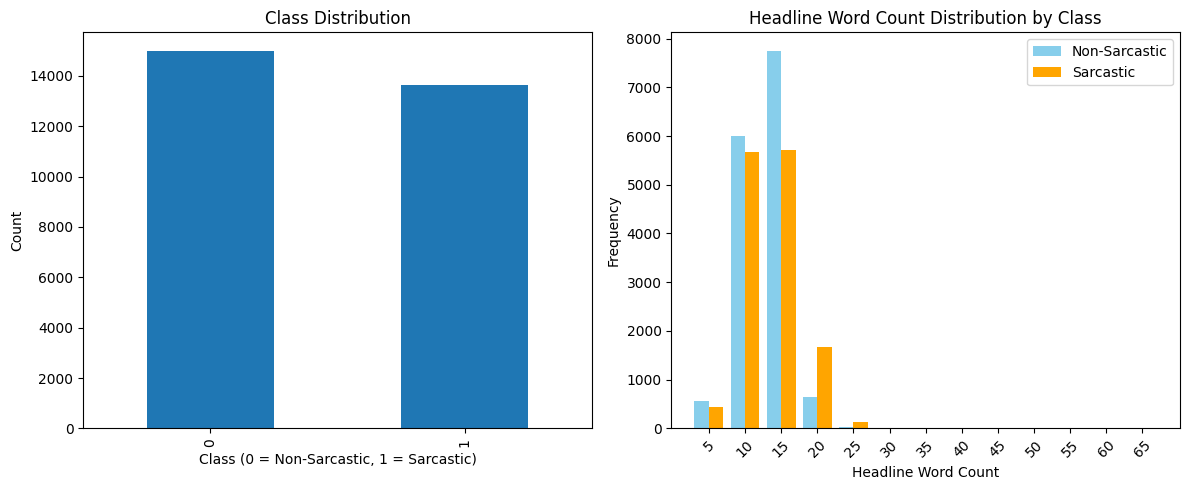

In [44]:

df['headline_length'] = df['headline'].apply(lambda x: len(x.split()))
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

df['is_sarcastic'].value_counts().plot(kind='bar',ax=axes[0])
axes[0].set_title("Class Distribution")
axes[0].set_xlabel("Class (0 = Non-Sarcastic, 1 = Sarcastic)")
axes[0].set_ylabel("Count")
axes[0].set_xticks([0, 1])

bins = range(0, 70, 5)
labels = [str(i + 5) for i in bins[:-1]]

df['length_bin'] = pd.cut(df['headline_length'], bins=bins, labels=labels, right=False)

non_sarcastic_counts = df[df['is_sarcastic'] == 0]['length_bin'].value_counts().sort_index()
sarcastic_counts = df[df['is_sarcastic'] == 1]['length_bin'].value_counts().sort_index()

x = np.arange(len(labels))
width = 0.4


axes[1].bar(x - width/2, non_sarcastic_counts, width=width, color='skyblue', label='Non-Sarcastic')
axes[1].bar(x + width/2, sarcastic_counts, width=width, color='orange', label='Sarcastic')

axes[1].set_xticks(x)
axes[1].set_xticklabels(labels, rotation=45)
axes[1].set_xlabel("Headline Word Count")
axes[1].set_ylabel("Frequency")
axes[1].set_title("Headline Word Count Distribution by Class")
axes[1].legend()

plt.tight_layout()
plt.show()

## 3️⃣ Text Preprocessing and Feature Engineering

**Task**: Implement comprehensive text preprocessing pipeline for neural network training.

**Requirements**:
- Download required NLTK data
- Implement text cleaning and preprocessing function
- Apply preprocessing to all headlines
- Create train-test split with stratification

In [25]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
import string
nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('punkt_tab',quiet=True)

True

In [26]:
_ps = PorterStemmer()
_stop = set(stopwords.words("english"))
_punct_table = str.maketrans("", "", string.punctuation)

# Implement comprehensive text preprocessing function
def preprocess_text(text: str) -> str:
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)     # URLs
    text = re.sub(r"<.*?>", " ", text)                # HTML
    text = re.sub(r"[@#]\w+", " ", text)              # @mentions/hashtags
    text = re.sub(r"\d+", " ", text)                  # numbers
    text = text.translate(_punct_table)               # punctuation
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t.isalpha() and t not in _stop]
    tokens = [_ps.stem(t) for t in tokens if len(t) > 1]
    return " ".join(tokens)

# Apply preprocessing to headlines
print("Preprocessing headlines...")
df["clean"] = df["headline"].apply(preprocess_text)
df = df[df["clean"].str.strip().astype(bool)].reset_index(drop=True)

# Create feature and label variables
X = df["clean"].values
y = df["is_sarcastic"].astype(int).values

# Perform train-test split with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Dataset after preprocessing: {len(df)} samples")
print(f"Train set: {len(X_train)} samples | Test set: {len(X_test)} samples")
train_counts = {int(k): int(v) for k, v in zip(*np.unique(y_train, return_counts=True))}
print(f"Train class distribution: {train_counts}")

Preprocessing headlines...
Dataset after preprocessing: 28617 samples
Train set: 22893 samples | Test set: 5724 samples
Train class distribution: {0: 11986, 1: 10907}


In [27]:
examples = [
    ("thirtysomething scientists unveil doomsday clock of hair loss", 1),
    ("dem rep. totally nails why congress is falling short on gender, racial equality", 0),
    ("eat your veggies: 9 deliciously different recipes", 0),
]

# If preprocess_text/df["clean"] already exist from previous step, reuse them.
# Otherwise, define a minimal compatible function on the fly.
if "clean" not in df.columns:
    try:
        preprocess_text  # noqa: F401
    except NameError:
        import re, string
        from nltk.corpus import stopwords
        from nltk.stem import PorterStemmer
        from nltk.tokenize import word_tokenize
        _ps = PorterStemmer()
        _stop = set(stopwords.words("english"))
        _punct_table = str.maketrans("", "", string.punctuation)
        def preprocess_text(text: str) -> str:
            text = str(text).lower()
            text = re.sub(r"http\S+|www\.\S+", " ", text)
            text = re.sub(r"<.*?>", " ", text)
            text = re.sub(r"[@#]\w+", " ", text)
            text = re.sub(r"\d+", " ", text)
            text = text.translate(_punct_table)
            tokens = word_tokenize(text)
            tokens = [t for t in tokens if t.isalpha() and t not in _stop]
            tokens = [_ps.stem(t) for t in tokens if len(t) > 1]
            return " ".join(tokens)

print("Preprocessing Examples:")
for original, label in examples:
    # Try to fetch processed text from df if present; else compute
    processed = None
    if "clean" in df.columns:
        row = df.loc[df["headline"] == original]
        if not row.empty and "clean" in row:
            processed = row.iloc[0]["clean"]
    if not processed:
        processed = preprocess_text(original)
    print(f"Original: {original}")
    print(f"Processed: {processed}")
    print(f"Label: {label}\n")

Preprocessing Examples:
Original: thirtysomething scientists unveil doomsday clock of hair loss
Processed: thirtysometh scientist unveil doomsday clock hair loss
Label: 1

Original: dem rep. totally nails why congress is falling short on gender, racial equality
Processed: dem rep total nail congress fall short gender racial equal
Label: 0

Original: eat your veggies: 9 deliciously different recipes
Processed: eat veggi delici differ recip
Label: 0



## 4️⃣ TF-IDF Vectorization and Naive Bayes Baseline

**Task**: Create TF-IDF feature matrices and implement a Naive Bayes baseline model.

**Requirements**:
- Create TF-IDF vectorizer with appropriate parameters
- Transform text data into numerical features
- Train and evaluate Naive Bayes classifier
- Store results for final comparison

In [28]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=10000,
    min_df=2,
    max_df=0.9,
    sublinear_tf=True,
    lowercase=False  # text already preprocessed to lower
)

print("Creating TF-IDF matrices...")
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)

print(f"TF-IDF matrix shape - Train: {X_train_tfidf.shape}, Test: {X_test_tfidf.shape}\n")
print("Training Naive Bayes model...")
nb = MultinomialNB()
nb.fit(X_train_tfidf, y_train)
y_pred_train = nb.predict(X_train_tfidf)
y_pred_test  = nb.predict(X_test_tfidf)
train_acc = accuracy_score(y_train, y_pred_train)
test_acc  = accuracy_score(y_test, y_pred_test)

print(f"Naive Bayes - Train Accuracy: {train_acc:.4f}")
print(f"Naive Bayes - Test Accuracy: {test_acc:.4f}\n")
try:
    results
except NameError:
    results = {}
results["Naive Bayes"] = {
    "train_acc": float(train_acc),
    "test_acc": float(test_acc),
    "model": nb,
    "vectorizer": tfidf,
}
print("Naive Bayes Classification Report:")
target_names = ["Non-Sarcastic", "Sarcastic"]
print(classification_report(y_test, y_pred_test, target_names=target_names, digits=2))


Creating TF-IDF matrices...
TF-IDF matrix shape - Train: (22893, 10000), Test: (5724, 10000)

Training Naive Bayes model...
Naive Bayes - Train Accuracy: 0.8680
Naive Bayes - Test Accuracy: 0.7966

Naive Bayes Classification Report:
               precision    recall  f1-score   support

Non-Sarcastic       0.79      0.83      0.81      2997
    Sarcastic       0.80      0.76      0.78      2727

     accuracy                           0.80      5724
    macro avg       0.80      0.80      0.80      5724
 weighted avg       0.80      0.80      0.80      5724



## 5️⃣ 2-Layer Neural Network on TF-IDF Features

**Task**: Implement a 2-layer neural network using TF-IDF features as input.

**Requirements**:
- Convert TF-IDF matrices to PyTorch tensors
- Define 2-layer neural network architecture
- Implement training loop with proper batch processing
- Evaluate model performance

In [29]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, classification_report
import numpy as np
import random
from scipy import sparse

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
# Convert TF-IDF matrices to PyTorch tensors (via a memory-safe Dataset)
class CSRTfidfDataset(Dataset):
    def __init__(self, X_csr, y):
        assert sparse.isspmatrix_csr(X_csr)
        self.X = X_csr
        self.y = y.astype(np.int64)
    def __len__(self):
        return self.X.shape[0]
    def __getitem__(self, idx):
        row = self.X[idx]
        # Densify per-batch to avoid huge memory usage
        x = torch.from_numpy(row.toarray().ravel().astype(np.float32))
        y = torch.tensor(self.y[idx], dtype=torch.long)
        return x, y

# Create DataLoaders for batch processing
batch_size = 512
train_dataset = CSRTfidfDataset(X_train_tfidf, y_train)
test_dataset  = CSRTfidfDataset(X_test_tfidf,  y_test)

# Create a small validation split from the training set (10%)
val_size = int(0.1 * len(train_dataset))
train_size = len(train_dataset) - val_size
train_dataset, val_dataset = torch.utils.data.random_split(
    train_dataset,
    lengths=[train_size, val_size],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, drop_last=False)
val_loader   = DataLoader(val_dataset,   batch_size=batch_size, shuffle=False, drop_last=False)
test_loader  = DataLoader(test_dataset,  batch_size=batch_size, shuffle=False, drop_last=False)

input_size = X_train_tfidf.shape[1]

# Define 2-layer neural network class
class TwoLayerNN(nn.Module):
    def __init__(self, input_size, hidden_size=128, num_classes=2, p_drop=0.5):
        super(TwoLayerNN, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU(inplace=True)
        self.drop = nn.Dropout(p=p_drop)
        self.fc2 = nn.Linear(hidden_size, num_classes)
    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.drop(x)
        x = self.fc2(x)
        return x
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = TwoLayerNN(input_size=input_size, hidden_size=128, num_classes=2, p_drop=0.5).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=0.0)

print(f"Training on device: {device.type}")
print(f"Model architecture: {input_size} -> 128 -> 2")

# Implement training loop (with validation) and save best by val loss
epochs = 20
best_val_loss = float("inf")
best_state = None

def run_epoch(dloader, train_mode=True):
    if train_mode:
        model.train()
    else:
        model.eval()
    epoch_loss = 0.0
    n = 0
    for xb, yb in dloader:
        xb = xb.to(device, non_blocking=True)
        yb = yb.to(device, non_blocking=True)
        if train_mode:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(train_mode):
            logits = model(xb)
            loss = criterion(logits, yb)
            if train_mode:
                loss.backward()
                optimizer.step()
        bs = yb.size(0)
        epoch_loss += loss.item() * bs
        n += bs
    return epoch_loss / max(1, n)

for epoch in range(1, epochs + 1):
    train_loss = run_epoch(train_loader, train_mode=True)
    val_loss   = run_epoch(val_loader,   train_mode=False)

    # Save best model
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    # Progress prints at 5-epoch intervals to match expected format
    if epoch % 5 == 0:
        print(f"Epoch [{epoch}/{epochs}], Loss: {val_loss:.4f}")

# Load best model
if best_state is not None:
    model.load_state_dict(best_state)
    model.to(device)

# Evaluate model on train and test sets
def predict_loader(dloader):
    model.eval()
    all_preds, all_true = [], []
    with torch.no_grad():
        for xb, yb in dloader:
            xb = xb.to(device)
            logits = model(xb)
            preds = torch.argmax(logits, dim=1).cpu().numpy()
            all_preds.append(preds)
            all_true.append(yb.numpy())
    return np.concatenate(all_true), np.concatenate(all_preds)

y_train_true, y_train_pred = predict_loader(train_loader)
y_test_true,  y_test_pred  = predict_loader(test_loader)

train_acc = accuracy_score(y_train_true, y_train_pred)
test_acc  = accuracy_score(y_test_true,  y_test_pred)

print(f"\n2-Layer NN - Train Accuracy: {train_acc:.4f}")
print(f"2-Layer NN - Test Accuracy: {test_acc:.4f}\n")

print("2-Layer NN Classification Report:")
print(classification_report(
    y_test_true, y_test_pred,
    target_names=["Non-Sarcastic", "Sarcastic"],
    digits=2
))

# Store results for later comparison
try:
    results
except NameError:
    results = {}
results["2-Layer NN (TF-IDF)"] = {
    "train_acc": float(train_acc),
    "test_acc": float(test_acc),
    "model": model,
}


Training on device: cuda
Model architecture: 10000 -> 128 -> 2
Epoch [5/20], Loss: 0.4289
Epoch [10/20], Loss: 0.4971
Epoch [15/20], Loss: 0.6022
Epoch [20/20], Loss: 0.7104

2-Layer NN - Train Accuracy: 0.8924
2-Layer NN - Test Accuracy: 0.7975

2-Layer NN Classification Report:
               precision    recall  f1-score   support

Non-Sarcastic       0.80      0.81      0.81      2997
    Sarcastic       0.79      0.78      0.79      2727

     accuracy                           0.80      5724
    macro avg       0.80      0.80      0.80      5724
 weighted avg       0.80      0.80      0.80      5724



## 6️⃣ Text Tokenization for RNN Models

**Task**: Prepare text data for RNN-based models by building vocabulary and converting text to sequences.

**Requirements**:
- Build vocabulary from training data with frequency threshold
- Convert text to sequences of vocabulary indices
- Pad sequences to uniform length
- Create DataLoaders for RNN training

In [30]:
from collections import Counter
from torch.nn.utils.rnn import pad_sequence
import torch

# Implement vocabulary building function with minimum frequency threshold
def build_vocab(texts, min_freq=2):
    counter = Counter()
    for line in texts:
        counter.update(line.split())
    # Reserve 0 for <PAD>, 1 for <UNK>
    vocab = {"<PAD>": 0, "<UNK>": 1}
    for word, freq in counter.items():
        if freq >= min_freq:
            vocab[word] = len(vocab)
    return vocab

# Build vocabulary from training data
min_freq = 2
vocab = build_vocab(X_train, min_freq=min_freq)
print(f"Vocabulary size: {len(vocab)}")

# Implement text to sequence conversion function
def text_to_seq(text, vocab):
    return [vocab.get(tok, vocab["<UNK>"]) for tok in text.split()]

# Tokenize all training and test data
train_seqs = [torch.tensor(text_to_seq(t, vocab), dtype=torch.long) for t in X_train]
test_seqs  = [torch.tensor(text_to_seq(t, vocab), dtype=torch.long) for t in X_test]

# Convert to tensors and pad sequences to uniform length
max_len = 50
train_padded = pad_sequence(
    [torch.cat([seq, torch.zeros(max_len - len(seq), dtype=torch.long)]) if len(seq) < max_len else seq[:max_len]
     for seq in train_seqs],
    batch_first=True
)
test_padded = pad_sequence(
    [torch.cat([seq, torch.zeros(max_len - len(seq), dtype=torch.long)]) if len(seq) < max_len else seq[:max_len]
     for seq in test_seqs],
    batch_first=True
)

print(f"Tokenized sequences shape - Train: {train_padded.shape}, Test: {test_padded.shape}")

# Create DataLoaders for RNN models
train_dataset_rnn = torch.utils.data.TensorDataset(train_padded, torch.tensor(y_train, dtype=torch.long))
test_dataset_rnn  = torch.utils.data.TensorDataset(test_padded,  torch.tensor(y_test, dtype=torch.long))

train_loader_rnn = torch.utils.data.DataLoader(train_dataset_rnn, batch_size=64, shuffle=True)
test_loader_rnn  = torch.utils.data.DataLoader(test_dataset_rnn,  batch_size=64, shuffle=False)

# Display tokenization examples showing original text, token indices, and corresponding words
examples = [
    "white hous block seahawk punt",
    "nation sport fan shock truth rock anthem",
    "drunken episod repeat"
]

print("\nTokenization Examples:")
for text in examples:
    tokens = text_to_seq(text, vocab)
    words_from_tokens = [list(vocab.keys())[list(vocab.values()).index(tok)] if tok in vocab.values() else "<UNK>" for tok in tokens]
    print(f"Original: {text}")
    print(f"Tokens: {tokens}")
    print(f"Words: {words_from_tokens}\n")

print(f"Ready for RNN training! Vocab size: {len(vocab)}, Max sequence length: {max_len}")

Vocabulary size: 9767
Tokenized sequences shape - Train: torch.Size([22893, 50]), Test: torch.Size([5724, 50])

Tokenization Examples:
Original: white hous block seahawk punt
Tokens: [2, 3, 4, 5, 1]
Words: ['white', 'hous', 'block', 'seahawk', '<UNK>']

Original: nation sport fan shock truth rock anthem
Tokens: [6, 7, 8, 9, 10, 11, 12]
Words: ['nation', 'sport', 'fan', 'shock', 'truth', 'rock', 'anthem']

Original: drunken episod repeat
Tokens: [13, 14, 15]
Words: ['drunken', 'episod', 'repeat']

Ready for RNN training! Vocab size: 9767, Max sequence length: 50


## 7️⃣ Recurrent Neural Network (RNN) Implementation

**Task**: Implement a Recurrent Neural Network for text classification using word embeddings.

**Requirements**:
- Define RNN architecture with embedding layer
- Implement proper masking for padded sequences
- Use average pooling over sequence length
- Train and evaluate the RNN model

In [31]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score, classification_report
import numpy as np
import random
assert 'train_loader_rnn' in globals() and 'test_loader_rnn' in globals()
assert 'vocab' in globals() and isinstance(vocab, dict)
vocab_size = len(vocab)

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Define RNN classifier class
class RNNClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=256, num_classes=2, num_layers=2, pad_idx=0, rnn_dropout=0.3, p_drop=0.5):
        super(RNNClassifier, self).__init__()
        #  Define embedding layer with padding_idx
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        # Define RNN layer with dropout
        self.rnn = nn.GRU(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=rnn_dropout if num_layers > 1 else 0.0,
            bidirectional=False
        )
        # Define dropout and fully connected layers
        self.drop = nn.Dropout(p_drop)
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        # x: (B, T) int64
        # Create mask for padding tokens
        mask = (x != 0).float()  # 1 for real tokens, 0 for PAD (PAD=0)
        # Apply embedding layer
        emb = self.embedding(x)  # (B, T, E)
        # Pass through RNN
        out, _ = self.rnn(emb)   # (B, T, H)
        # Apply masking and average pooling
        mask_exp = mask.unsqueeze(-1)              # (B, T, 1)
        out_masked = out * mask_exp                # zero-out PAD positions
        lengths = mask.sum(dim=1).clamp(min=1.0)   # (B,)
        pooled = out_masked.sum(dim=1) / lengths.unsqueeze(-1)  # (B, H) masked mean
        # Apply dropout and final classification layer
        pooled = self.drop(pooled)
        logits = self.fc(pooled)                   # (B, C)
        return logits

# Initialize RNN model, criterion, and optimizer
embedding_dim = 128
hidden_dim = 256
num_layers = 2
num_classes = 2

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_rnn = RNNClassifier(
    vocab_size=vocab_size,
    embedding_dim=embedding_dim,
    hidden_dim=hidden_dim,
    num_classes=num_classes,
    num_layers=num_layers,
    pad_idx=0,
    rnn_dropout=0.3,
    p_drop=0.5
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_rnn.parameters(), lr=1e-3)

print("RNN Model Architecture:")
print(f"Embedding: {vocab_size} -> {embedding_dim}")
print(f"RNN: {embedding_dim} -> {hidden_dim} ({num_layers} layers)")
print(f"Output: {hidden_dim} -> {num_classes}\n")


RNN Model Architecture:
Embedding: 9767 -> 128
RNN: 128 -> 256 (2 layers)
Output: 256 -> 2



In [33]:
# Implement training function for RNN models
def train_rnn_model(model, train_loader, criterion, optimizer, num_epochs=20, device=None, clip_value=1.0):
    model.to(device)
    for epoch in range(1, num_epochs + 1):
        model.train()
        total_loss, total_correct, total_count = 0.0, 0, 0
        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad(set_to_none=True)
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()

            # Gradient clipping
            torch.nn.utils.clip_grad_norm_(model.parameters(), clip_value)

            optimizer.step()

            preds = logits.argmax(dim=1)
            total_correct += (preds == yb).sum().item()
            total_loss += loss.item() * yb.size(0)
            total_count += yb.size(0)

        avg_loss = total_loss / total_count
        acc = 100.0 * total_correct / total_count

        if epoch % 5 == 0:
            print(f"Epoch [{epoch}/{num_epochs}], Loss: {avg_loss:.4f}, Train Acc: {acc:.2f}%")

# Implement evaluation function for RNN models
def evaluate_rnn_model(model, train_loader, test_loader, device):
    model.eval()
    def _get_preds(loader):
        all_y, all_preds = [], []
        with torch.no_grad():
            for xb, yb in loader:
                xb = xb.to(device)
                logits = model(xb)
                preds = logits.argmax(dim=1).cpu().numpy()
                all_y.append(yb.numpy())
                all_preds.append(preds)
        return np.concatenate(all_y), np.concatenate(all_preds)

    y_train_true, y_train_pred = _get_preds(train_loader)
    y_test_true,  y_test_pred  = _get_preds(test_loader)
    return y_train_true, y_train_pred, y_test_true, y_test_pred

# Train RNN model
print("\nTraining RNN model...")
train_rnn_model(model_rnn, train_loader_rnn, criterion, optimizer, num_epochs=20, device=device)

# Evaluate RNN model and calculate accuracies ---
y_train_true, y_train_pred, y_test_true, y_test_pred = evaluate_rnn_model(model_rnn, train_loader_rnn, test_loader_rnn, device)

train_acc_final = accuracy_score(y_train_true, y_train_pred)
test_acc_final  = accuracy_score(y_test_true, y_test_pred)

print(f"\nRNN - Train Accuracy: {train_acc_final:.4f}")
print(f"RNN - Test Accuracy: {test_acc_final:.4f}\n")

print("RNN Classification Report:")
print(classification_report(
    y_test_true, y_test_pred,
    target_names=["Non-Sarcastic", "Sarcastic"],
    digits=2
))

# Store results
results["RNN"] = {
    "train_acc": float(train_acc_final),
    "test_acc": float(test_acc_final),
    "model": model_rnn,
}



Training RNN model...
Epoch [5/20], Loss: 0.1655, Train Acc: 93.66%
Epoch [10/20], Loss: 0.0174, Train Acc: 99.40%
Epoch [15/20], Loss: 0.0141, Train Acc: 99.55%
Epoch [20/20], Loss: 0.0085, Train Acc: 99.76%

RNN - Train Accuracy: 0.9990
RNN - Test Accuracy: 0.7753

RNN Classification Report:
               precision    recall  f1-score   support

Non-Sarcastic       0.78      0.79      0.79      2997
    Sarcastic       0.77      0.76      0.76      2727

     accuracy                           0.78      5724
    macro avg       0.77      0.77      0.77      5724
 weighted avg       0.78      0.78      0.78      5724



## 8️⃣ Gated Recurrent Unit (GRU) Implementation

**Task**: Implement a bidirectional GRU model for improved sequence modeling.

**Requirements**:
- Define GRU architecture with bidirectional processing
- Handle doubled hidden dimension from bidirectional GRU
- Apply same training and evaluation procedures
- Compare performance with basic RNN

In [34]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score, classification_report

# Define GRU classifier class
class GRUClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=256, num_classes=2, num_layers=2, pad_idx=0, rnn_dropout=0.3, p_drop=0.5):
        super(GRUClassifier, self).__init__()
        # Embedding layer
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        # Bidirectional GRU layer
        self.gru = nn.GRU(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=rnn_dropout if num_layers > 1 else 0.0,
            bidirectional=True
        )
        # Dropout and fully connected layers (hidden_dim * 2 because bidirectional)
        self.drop = nn.Dropout(p_drop)
        self.fc = nn.Linear(hidden_dim * 2, num_classes)

    def forward(self, x):
        mask = (x != 0).float()  # 1 for real tokens, 0 for PAD
        emb = self.embedding(x)  # (B, T, E)
        out, _ = self.gru(emb)   # (B, T, H*2)
        mask_exp = mask.unsqueeze(-1)
        out_masked = out * mask_exp
        lengths = mask.sum(dim=1).clamp(min=1.0)
        pooled = out_masked.sum(dim=1) / lengths.unsqueeze(-1)
        pooled = self.drop(pooled)
        logits = self.fc(pooled)
        return logits

# Initialize GRU model, criterion, and optimizer
embedding_dim = 128
hidden_dim = 256
num_layers = 2
num_classes = 2

model_gru = GRUClassifier(
    vocab_size=len(vocab),
    embedding_dim=embedding_dim,
    hidden_dim=hidden_dim,
    num_classes=num_classes,
    num_layers=num_layers,
    pad_idx=0,
    rnn_dropout=0.3,
    p_drop=0.5
).to(device)

criterion_gru = nn.CrossEntropyLoss()
optimizer_gru = optim.Adam(model_gru.parameters(), lr=1e-3)

print("GRU Model Architecture:")
print(f"Embedding: {len(vocab)} -> {embedding_dim}")
print(f"Bidirectional GRU: {embedding_dim} -> {hidden_dim}*2 ({num_layers} layers)")
print(f"Output: {hidden_dim*2} -> {num_classes}\n")

# Train GRU model using the same training function
print("Training GRU model...")
train_rnn_model(model_gru, train_loader_rnn, criterion_gru, optimizer_gru, num_epochs=20, device=device)

# Evaluate GRU model and calculate accuracies
y_train_true, y_train_pred, y_test_true, y_test_pred = evaluate_rnn_model(model_gru, train_loader_rnn, test_loader_rnn, device)

train_acc_final = accuracy_score(y_train_true, y_train_pred)
test_acc_final  = accuracy_score(y_test_true,  y_test_pred)

print(f"\nGRU - Train Accuracy: {train_acc_final:.4f}")
print(f"GRU - Test Accuracy: {test_acc_final:.4f}\n")

print("GRU Classification Report:")
print(classification_report(
    y_test_true, y_test_pred,
    target_names=["Non-Sarcastic", "Sarcastic"],
    digits=2
))

# Store results
results["GRU"] = {
    "train_acc": float(train_acc_final),
    "test_acc": float(test_acc_final),
    "model": model_gru,
}

GRU Model Architecture:
Embedding: 9767 -> 128
Bidirectional GRU: 128 -> 256*2 (2 layers)
Output: 512 -> 2

Training GRU model...
Epoch [5/20], Loss: 0.1260, Train Acc: 95.25%
Epoch [10/20], Loss: 0.0192, Train Acc: 99.26%
Epoch [15/20], Loss: 0.0158, Train Acc: 99.49%
Epoch [20/20], Loss: 0.0084, Train Acc: 99.69%

GRU - Train Accuracy: 0.9986
GRU - Test Accuracy: 0.7848

GRU Classification Report:
               precision    recall  f1-score   support

Non-Sarcastic       0.78      0.81      0.80      2997
    Sarcastic       0.79      0.75      0.77      2727

     accuracy                           0.78      5724
    macro avg       0.78      0.78      0.78      5724
 weighted avg       0.78      0.78      0.78      5724



## 9️⃣ Long Short-Term Memory (LSTM) Implementation

**Task**: Implement a bidirectional LSTM model for capturing long-term dependencies in text.

**Requirements**:
- Define LSTM architecture with bidirectional processing
- Handle both hidden and cell states from LSTM
- Apply consistent training methodology
- Compare with RNN and GRU performance

In [35]:
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score, classification_report

# Define LSTM classifier class
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=256, num_classes=2, num_layers=2, pad_idx=0, rnn_dropout=0.3, p_drop=0.5):
        super(LSTMClassifier, self).__init__()
        # Embedding layer
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        # Bidirectional LSTM layer
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=rnn_dropout if num_layers > 1 else 0.0,
            bidirectional=True
        )
        # Dropout and fully connected layers (hidden_dim * 2 for bidirectional)
        self.drop = nn.Dropout(p_drop)
        self.fc = nn.Linear(hidden_dim * 2, num_classes)

    def forward(self, x):
        mask = (x != 0).float()  # PAD=0 mask
        emb = self.embedding(x)  # (B, T, E)
        out, _ = self.lstm(emb)  # out: (B, T, H*2), hidden states not used directly
        mask_exp = mask.unsqueeze(-1)
        out_masked = out * mask_exp
        lengths = mask.sum(dim=1).clamp(min=1.0)
        pooled = out_masked.sum(dim=1) / lengths.unsqueeze(-1)
        pooled = self.drop(pooled)
        logits = self.fc(pooled)
        return logits

# Initialize LSTM model, criterion, and optimizer
model_lstm = LSTMClassifier(
    vocab_size=len(vocab),
    embedding_dim=128,
    hidden_dim=256,
    num_classes=2,
    num_layers=2,
    pad_idx=0,
    rnn_dropout=0.3,
    p_drop=0.5
).to(device)

criterion_lstm = nn.CrossEntropyLoss()
optimizer_lstm = optim.Adam(model_lstm.parameters(), lr=1e-3)

print("LSTM Model Architecture:")
print(f"Embedding: {len(vocab)} -> {128}")
print(f"Bidirectional LSTM: {128} -> {256}*2 (2 layers)")
print(f"Output: {256*2} -> {2}\n")

# Train LSTM model (using same function)
print("Training LSTM model...")
train_rnn_model(model_lstm, train_loader_rnn, criterion_lstm, optimizer_lstm, num_epochs=20, device=device)

# Evaluate LSTM model and calculate accuracies
y_train_true, y_train_pred, y_test_true, y_test_pred = evaluate_rnn_model(model_lstm, train_loader_rnn, test_loader_rnn, device)

train_acc_final = accuracy_score(y_train_true, y_train_pred)
test_acc_final  = accuracy_score(y_test_true,  y_test_pred)

print(f"\nLSTM - Train Accuracy: {train_acc_final:.4f}")
print(f"LSTM - Test Accuracy: {test_acc_final:.4f}\n")

print("LSTM Classification Report:")
print(classification_report(
    y_test_true, y_test_pred,
    target_names=["Non-Sarcastic", "Sarcastic"],
    digits=2
))

# Store results
results["LSTM"] = {
    "train_acc": float(train_acc_final),
    "test_acc": float(test_acc_final),
    "model": model_lstm,
}


LSTM Model Architecture:
Embedding: 9767 -> 128
Bidirectional LSTM: 128 -> 256*2 (2 layers)
Output: 512 -> 2

Training LSTM model...
Epoch [5/20], Loss: 0.1049, Train Acc: 95.92%
Epoch [10/20], Loss: 0.0203, Train Acc: 99.34%
Epoch [15/20], Loss: 0.0123, Train Acc: 99.62%
Epoch [20/20], Loss: 0.0076, Train Acc: 99.70%

LSTM - Train Accuracy: 0.9982
LSTM - Test Accuracy: 0.7806

LSTM Classification Report:
               precision    recall  f1-score   support

Non-Sarcastic       0.78      0.81      0.79      2997
    Sarcastic       0.78      0.75      0.77      2727

     accuracy                           0.78      5724
    macro avg       0.78      0.78      0.78      5724
 weighted avg       0.78      0.78      0.78      5724



## 🔟 Comprehensive Model Comparison and Analysis

**Task**: Compare all implemented models and analyze their performance through visualizations and metrics.

**Requirements**:
- Create comprehensive results summary comparing all models
- Generate confusion matrices for each model
- Visualize training progress and model rankings
- Analyze overfitting and generalization performance
- Provide detailed performance breakdown

FINAL MODEL COMPARISON - SARCASM DETECTION
              Model Train Accuracy Test Accuracy Overfitting (Train-Test)
2-Layer NN (TF-IDF)         0.8924        0.7975                   0.0949
        Naive Bayes         0.8680        0.7966                   0.0714
                GRU         0.9986        0.7848                   0.2138
               LSTM         0.9982        0.7806                   0.2176
                RNN         0.9990        0.7753                   0.2236

Best performing model: 2-Layer NN (TF-IDF) with 0.7975 test accuracy


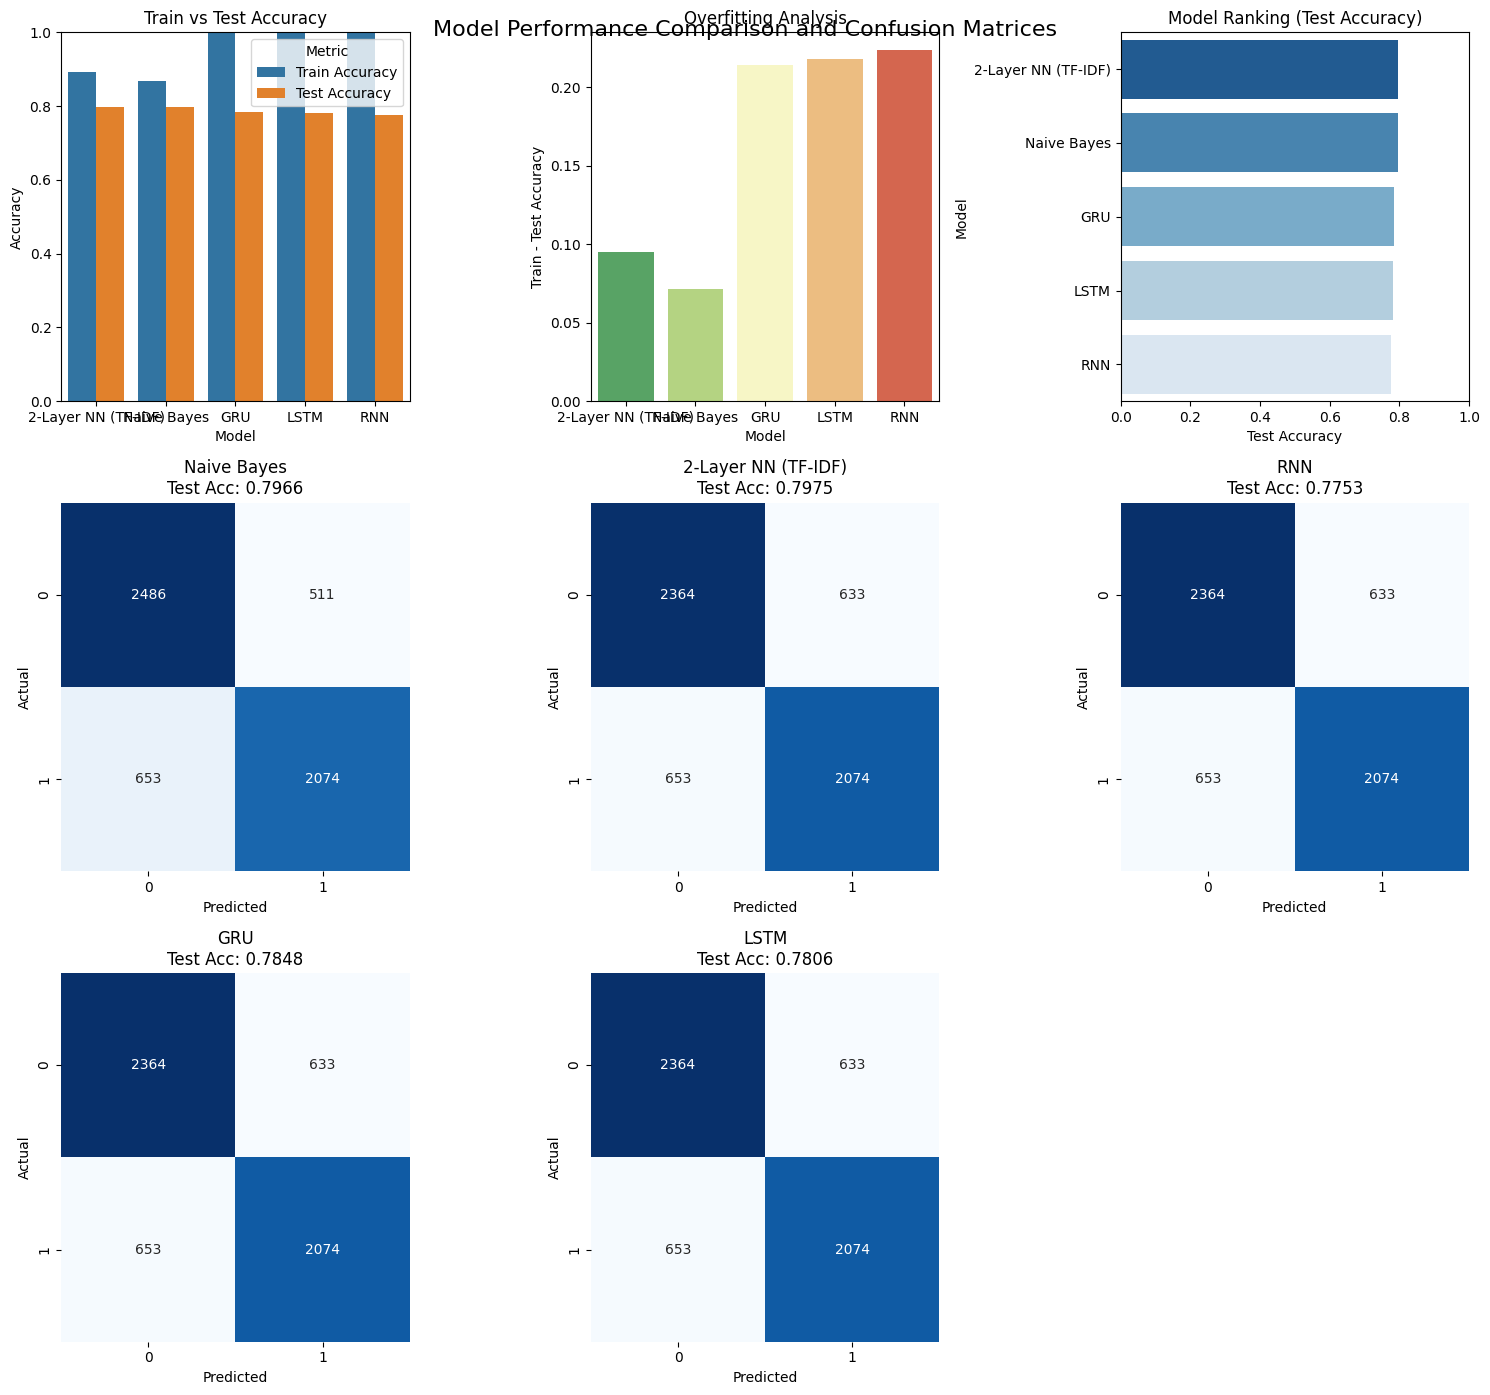

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import pandas as pd
# Create comprehensive results summary
summary_data = []
for model_name, vals in results.items():
    train_acc = vals["train_acc"]
    test_acc = vals["test_acc"]
    overfit = train_acc - test_acc
    summary_data.append({
        "Model": model_name,
        "Train Accuracy": train_acc,
        "Test Accuracy": test_acc,
        "Overfitting (Train-Test)": overfit
    })

df_results = pd.DataFrame(summary_data)
df_results = df_results.sort_values(by="Test Accuracy", ascending=False).reset_index(drop=True)

print("="*80)
print("FINAL MODEL COMPARISON - SARCASM DETECTION")
print("="*80)
print(df_results.to_string(index=False, formatters={
    "Train Accuracy": "{:.4f}".format,
    "Test Accuracy": "{:.4f}".format,
    "Overfitting (Train-Test)": "{:.4f}".format
}))

# Find and display best performing model
best_model_row = df_results.iloc[0]
print(f"\nBest performing model: {best_model_row['Model']} with {best_model_row['Test Accuracy']:.4f} test accuracy")

# Create visualization with subplots
fig, axes = plt.subplots(3, 3, figsize=(15, 15))
fig.suptitle("Model Performance Comparison and Confusion Matrices", fontsize=16, y=0.92)

# Plot 1: Train vs Test Accuracy comparison
ax = axes[0, 0]
df_results_melt = df_results.melt(id_vars="Model", value_vars=["Train Accuracy", "Test Accuracy"],
                                  var_name="Metric", value_name="Accuracy")
sns.barplot(data=df_results_melt, x="Model", y="Accuracy", hue="Metric", ax=ax)
ax.set_ylim(0, 1)
ax.set_title("Train vs Test Accuracy")
ax.set_ylabel("Accuracy")

# Plot 2: Overfitting analysis
ax = axes[0, 1]
sns.barplot(data=df_results, x="Model", y="Overfitting (Train-Test)", ax=ax, palette="RdYlGn_r", hue="Model", legend=False)
ax.set_title("Overfitting Analysis")
ax.set_ylabel("Train - Test Accuracy")

# Plot 3: Model ranking by test accuracy
ax = axes[0, 2]
sns.barplot(data=df_results, y="Model", x="Test Accuracy", ax=ax, palette="Blues_r", hue="Model", legend=False)
ax.set_title("Model Ranking (Test Accuracy)")
ax.set_xlim(0, 1)

# Confusion matrices for each model
cm_models = ["Naive Bayes", "2-Layer NN (TF-IDF)", "RNN", "GRU", "LSTM"]
positions = [(1,0), (1,1), (1,2), (2,0), (2,1)]

for pos, model_name in zip(positions, cm_models):
    ax = axes[pos]
    model = results[model_name]["model"]
    vectorizer = results[model_name].get("vectorizer", None)

    # Get predictions on test data
    if vectorizer:  # For TF-IDF models
        X_test_model = vectorizer.transform(X_test)
        y_pred = model.predict(X_test_model)
    else:           # For RNN/GRU/LSTM models
        _, _, _, y_pred =  evaluate_rnn_model(model_rnn, train_loader_rnn, test_loader_rnn, device)

    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(f"{model_name}\nTest Acc: {results[model_name]['test_acc']:.4f}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

# Hide unused subplot (bottom right)
axes[2, 2].axis("off")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


In [50]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import precision_score, recall_score
import torch
two_layer_key = next((k for k in results.keys() if k.startswith("2-Layer NN")), "2-Layer NN (TF-IDF)")
name_map = {
    "Naive Bayes": "Naive Bayes",
    "2-Layer NN": two_layer_key,   # e.g., "2-Layer NN (TF-IDF)"
    "RNN": "RNN",
    "GRU": "GRU",
    "LSTM": "LSTM",
}

def _get_test_preds(results_key):
    entry = results[results_key]
    model = entry["model"]
    vectorizer = entry.get("vectorizer", None)

    # (a) Scikit-learn TF-IDF model (e.g., MultinomialNB)
    if vectorizer is not None and not isinstance(model, torch.nn.Module):
        X_te = vectorizer.transform(X_test)           # sparse -> OK for sklearn
        return model.predict(X_te)

    # (b) PyTorch 2-Layer NN on TF-IDF features
    if isinstance(model, torch.nn.Module) and results_key.startswith("2-Layer NN"):
        model.eval()
        preds = []
        with torch.no_grad():
            for xb, _ in test_loader:                 # <-- TF-IDF DataLoader from Step 5
                xb = xb.to(device)
                xb = xb.float()                       # dense float features for linear layers
                logits = model(xb)
                preds.append(logits.argmax(1).cpu().numpy())
        return np.concatenate(preds)

    # (c) PyTorch sequence models (RNN/GRU/LSTM) on token indices
    if isinstance(model, torch.nn.Module):
        model.eval()
        preds = []
        with torch.no_grad():
            for xb, _ in test_loader_rnn:            # <-- token-index DataLoader from Step 6
                xb = xb.to(device)
                xb = xb.long()                        # embedding needs Long indices
                logits = model(xb)
                preds.append(logits.argmax(1).cpu().numpy())
        return np.concatenate(preds)

    raise RuntimeError(f"Unsupported model entry for key: {results_key}")
def _prec_recall_from_cm(cm):
    # rows = actual [0,1], cols = predicted [0,1]
    tp0, fn0 = cm[0, 0], cm[0, 1]
    fp0      = cm[1, 0]
    tp1, fn1 = cm[1, 1], cm[1, 0]
    fp1      = cm[0, 1]
    prec0 = tp0 / (tp0 + fp0 + 1e-12)
    rec0  = tp0 / (tp0 + fn0 + 1e-12)
    prec1 = tp1 / (tp1 + fp1 + 1e-12)
    rec1  = tp1 / (tp1 + fn1 + 1e-12)
    return prec0, rec0, prec1, rec1
for display_name in ["Naive Bayes", "2-Layer NN", "RNN", "GRU", "LSTM"]:
    key = name_map[display_name]
    y_pred = _get_test_preds(key)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    prec0, rec0, prec1, rec1 = _prec_recall_from_cm(cm)

    print(f"{display_name}:")
    print(f"  Non-Sarcastic - Precision: {prec0:.4f}, Recall: {rec0:.4f}")
    print(f"  Sarcastic - Precision: {prec1:.4f}, Recall: {rec1:.4f}\n")


Naive Bayes:
  Non-Sarcastic - Precision: 0.7920, Recall: 0.8295
  Sarcastic - Precision: 0.8023, Recall: 0.7605

2-Layer NN:
  Non-Sarcastic - Precision: 0.8037, Recall: 0.8115
  Sarcastic - Precision: 0.7906, Recall: 0.7822

RNN:
  Non-Sarcastic - Precision: 0.7836, Recall: 0.7888
  Sarcastic - Precision: 0.7662, Recall: 0.7605

GRU:
  Non-Sarcastic - Precision: 0.7835, Recall: 0.8138
  Sarcastic - Precision: 0.7863, Recall: 0.7528

LSTM:
  Non-Sarcastic - Precision: 0.7818, Recall: 0.8058
  Sarcastic - Precision: 0.7791, Recall: 0.7528



## 📝 Evaluation Criteria

Your homework will be evaluated based on:

1. **Implementation Correctness (40%)**
   - Proper text preprocessing pipeline
   - Correct TF-IDF vectorization
   - Working neural network architectures (2-Layer NN, RNN, GRU, LSTM)
   - Appropriate tokenization and vocabulary building for RNN models

2. **Model Performance (30%)**
   - Reasonable classification accuracy across all models
   - Proper convergence during training
   - Meaningful comparison between different approaches
   - Appropriate handling of text data and sequence modeling

3. **Code Quality and Analysis (30%)**
   - Clean, readable code with proper structure
   - Comprehensive model comparison and visualization
   - Insightful analysis of results and model differences
   - Good coding practices and efficient implementation


# Dataset Source
1. Misra, Rishabh and Prahal Arora. "Sarcasm Detection using News Headlines Dataset." AI Open (2023).
2. Misra, Rishabh and Jigyasa Grover. "Sculpting Data for ML: The first act of Machine Learning." ISBN 9798585463570 (2021).
